#Import

In [1]:
from PIL import Image  # Import the Image module from Pillow
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier

#MNIST classification using CNN model

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 18ms/step - accuracy: 0.9504 - loss: 0.1620 - val_accuracy: 0.9773 - val_loss: 0.0709
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 35s 23ms/step - accuracy: 0.9841 - loss: 0.0513 - val_accuracy: 0.9853 - val_loss: 0.0483
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.9888 - loss: 0.0363 - val_accuracy: 0.9890 - val_loss: 0.0363
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 41s 17ms/step - accuracy: 0.9921 - loss: 0.0252 - val_accuracy: 0.9879 - val_loss: 0.0416
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 17ms/step - accuracy: 0.9940 - loss: 0.0194 - val_accuracy: 0.9871 - val_loss: 0.0491
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


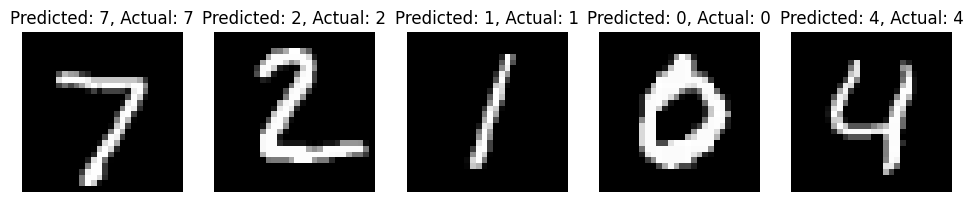

In [2]:
# Import Libraries
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Load the MNIST Dataset
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Preprocess the Data
x_train = x_train.reshape((60000, 28, 28, 1)).astype('float32') / 255.0
x_test = x_test.reshape((10000, 28, 28, 1)).astype('float32') / 255.0

# Build a Simple CNN Model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')  # 10 classes for digits 0-9
])

# Compile the Model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Train the Model
model.fit(x_train, y_train, epochs=5, validation_split=0.2)

# Make Predictions on Test Set
predictions = model.predict(x_test)

# Display Sample Predictions
plt.figure(figsize=(12, 6))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Predicted: {tf.argmax(predictions[i]).numpy()}, Actual: {y_test[i]}")
    plt.axis('off')
plt.show()


#Object Detection

In [ ]:
# Set up the environment
!git clone https://github.com/ultralytics/yolov5  # Clone the YOLOv5 repo
%cd yolov5
!pip install -r requirements.txt  # Install requirements

# Import libraries
import torch
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load a pre-trained YOLOv5 model
model = torch.hub.load('ultralytics/yolov5', 'yolov5s')  # Load YOLOv5s model (small)


Cloning into 'yolov5'...
remote: Enumerating objects: 16977, done.
remote: Counting objects: 100% (172/172), done.
remote: Compressing objects: 100% (115/115), done.
remote: Total 16977 (delta 89), reused 111 (delta 57), pack-reused 16805 (from 1)
Receiving objects: 100% (16977/16977), 15.71 MiB | 10.06 MiB/s, done.
Resolving deltas: 100% (11618/11618), done.
/content/yolov5/yolov5/yolov5/yolov5


Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master
YOLOv5 🚀 2024-10-7 Python-3.10.12 torch-2.4.1+cu121 CPU

100%|██████████| 14.1M/14.1M [00:00<00:00, 123MB/s]

Fusing layers... 
YOLOv5s summary: 213 layers, 7225885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


In [ ]:
pip install requests


In [ ]:
import requests

# Define the URL of the image
url = 'https://github.com/ultralytics/yolov5/releases/download/v1.0/zidane.jpg'

# Send a GET request to the URL
response = requests.get(url)

# Open a file in binary write mode
with open('zidane.jpg', 'wb') as f:
    f.write(response.content)

print("Image downloaded successfully!")


Image downloaded successfully!


Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master
YOLOv5 🚀 2024-10-7 Python-3.10.12 torch-2.4.1+cu121 CPU

Fusing layers... 
YOLOv5s summary: 213 layers, 7225885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 
/root/.cache/torch/hub/ultralytics_yolov5_master/models/common.py:892: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):


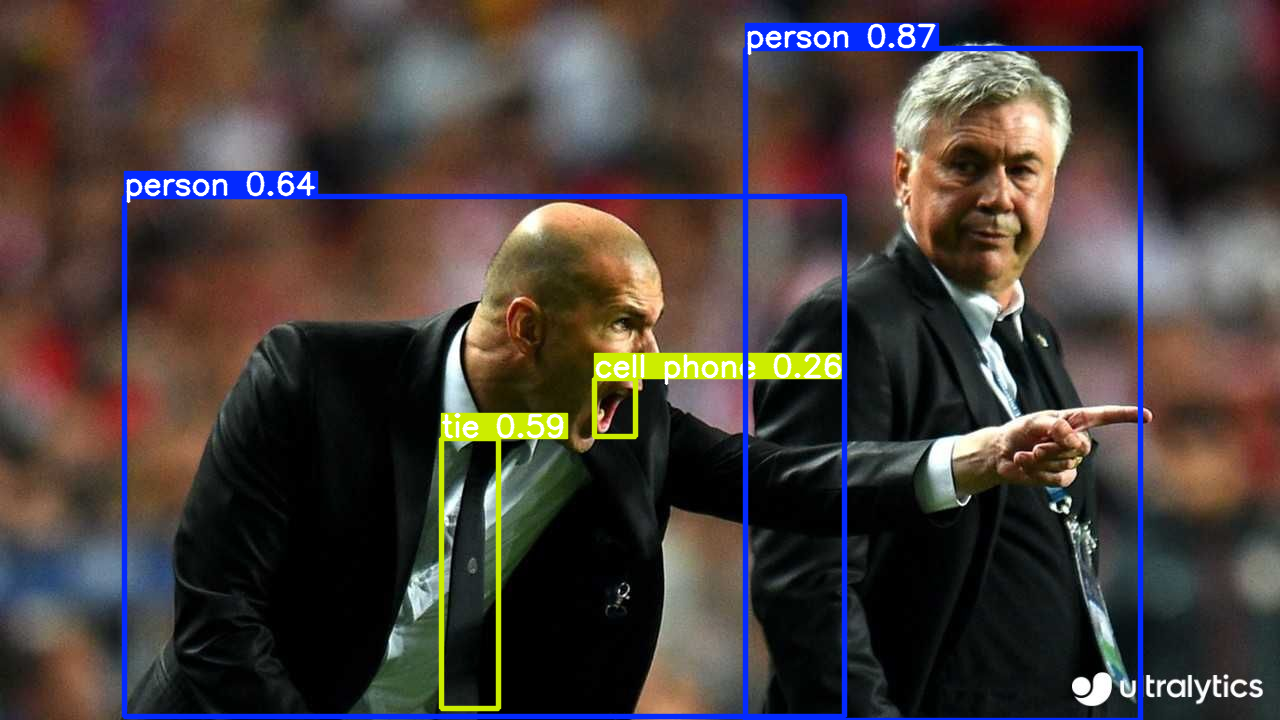

In [ ]:
import torch

# Load the YOLOv5 model
model = torch.hub.load('ultralytics/yolov5', 'yolov5s')

# Load the image
img = 'zidane.jpg'  # path to your image

# Perform inference
results = model(img)

# Show results
results.show()  # This will display the image with detections


/root/.cache/torch/hub/ultralytics_yolov5_master/models/common.py:892: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):


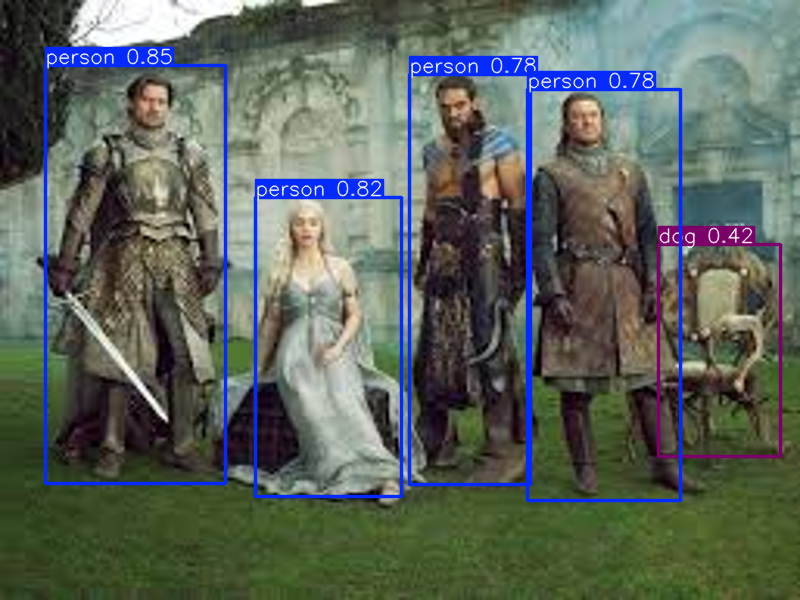

In [ ]:
img_path = '/content/game of thrones.jpeg'  # path to your image
image = Image.open(img_path)

# Resize the image
resized_image = image.resize((800, 600))

# Convert the resized image to a format compatible with the model (e.g., NumPy array)
# If your model requires a specific input format, you may need to adjust the image further.
img_array = np.array(resized_image)

# Perform inference
results = model(img_array)

# Show results
results.show()  # This will display the image with detections

# If you want to visualize the resized image
plt.imshow(resized_image)
plt.axis('off')
plt.title('Resized Image')
plt.show()


/root/.cache/torch/hub/ultralytics_yolov5_master/models/common.py:892: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):


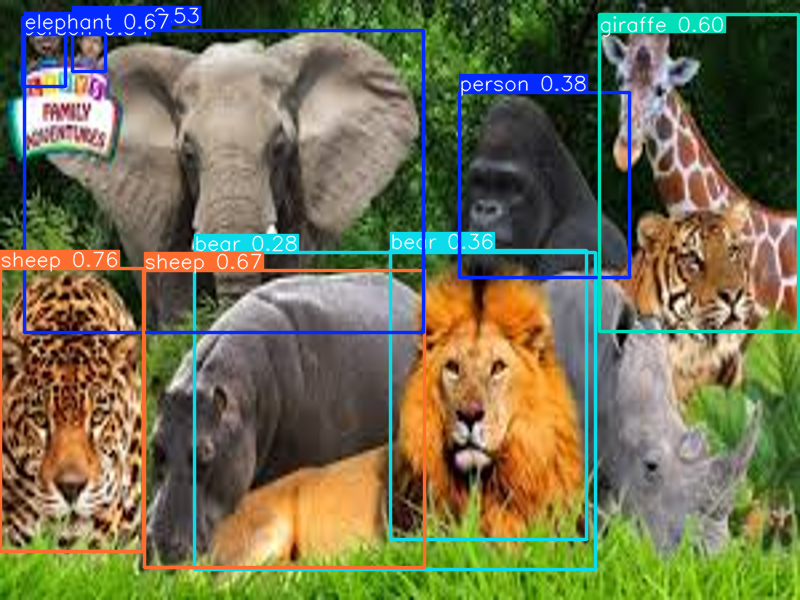

In [ ]:
img_path = '/content/animals.jpeg'  # path to your image
image = Image.open(img_path)

# Resize the image
resized_image = image.resize((800, 600))

# Convert the resized image to a format compatible with the model (e.g., NumPy array)
# If your model requires a specific input format, you may need to adjust the image further.
img_array = np.array(resized_image)

# Perform inference
results = model(img_array)

# Show results
results.show()  # This will display the image with detections

# If you want to visualize the resized image
plt.imshow(resized_image)
plt.axis('off')
plt.title('Resized Image')
plt.show()


#Segmentation

In [ ]:
pip install tensorflow tensorflow-datasets matplotlib numpy


#HomeWork2

Run this cell first to load the required dataset

In [3]:
# Load the MNIST dataset
mnist = fetch_openml('mnist_784', version=1)
X, y = mnist['data'], mnist['target']

# Preprocess the Data
X = X / 255.0  # Normalize pixel values to [0, 1]
y = y.astype(np.uint8)  # Convert labels to integers

#  Split the Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the data for SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


##Part1 : In this section, we want to classify the MNIST dataset using Random Forest, Logistic Regression, and Neural Networks. We will print the accuracy for each model. The code for Random Forest will serve as an example, and you should complete the code for Logistic Regression and Neural Networks accordingly.

In [4]:
# Train Different Classifiers

# 1. Random Forest
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)
y_pred_rf = rf_classifier.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)


In [5]:
# 2. Logistic Regression
logistic_classifier = LogisticRegression(max_iter=1000, random_state=42)
logistic_classifier.fit(X_train, y_train)

y_pred_logistic = logistic_classifier.predict(X_test)
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)

In [6]:
# 3. MLP (Neural Network)
mlp = MLPClassifier(hidden_layer_sizes=(100,), max_iter=200, random_state=42)
mlp.fit(X_train, y_train)

y_pred_mlp = mlp.predict(X_test)
accuracy_mlp = accuracy_score(y_test, y_pred_mlp)

In [ ]:
# Step 6: Print Accuracy Results
print(f'Logistic Regression Accuracy: {accuracy_logistic * 100:.2f}%')
print(f'Random Forest Accuracy: {accuracy_rf * 100:.2f}%')
print(f'MLP Accuracy: {accuracy_mlp * 100:.2f}%')

Logistic Regression Accuracy: 91.91%
Random Forest Accuracy: 96.75%
MLP Accuracy: 97.57%


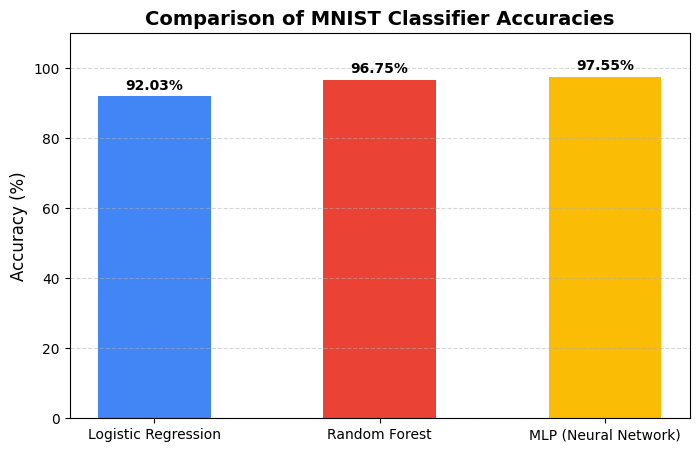

In [7]:
import matplotlib.pyplot as plt

# Model names and their corresponding accuracies
models = ['Logistic Regression', 'Random Forest', 'MLP (Neural Network)']
accuracies = [accuracy_logistic * 100, accuracy_rf * 100, accuracy_mlp * 100]

# Create the bar plot
plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies, color=['#4285F4', '#EA4335', '#FBBC05'], width=0.5)

# Add values on top of the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.title('Comparison of MNIST Classifier Accuracies', fontsize=14, fontweight='bold')
plt.ylabel('Accuracy (%)', fontsize=12)
plt.ylim(0, 110)  # Limit to 110% to make space for labels
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Total misclassified by MLP: 343 out of 14000 samples.


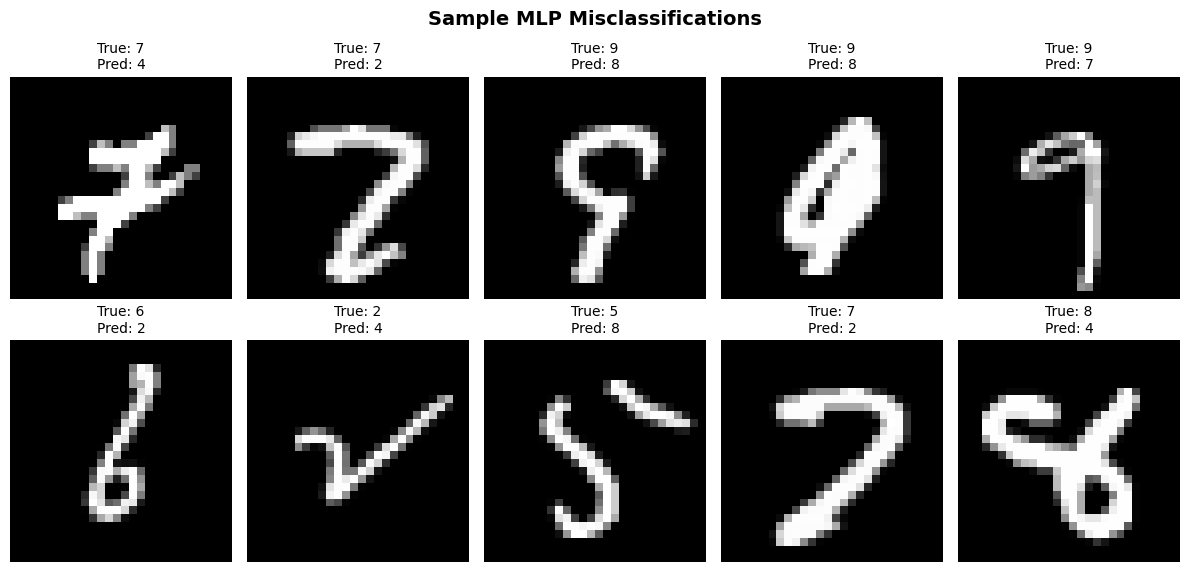

In [8]:
# Identify misclassified samples
misclassified_indices = np.where(y_pred_mlp != y_test.values)[0]
print(f"Total misclassified by MLP: {len(misclassified_indices)} out of {len(y_test)} samples.")

# Plot a few sample misclassified digits
plt.figure(figsize=(12, 6))
num_samples = min(10, len(misclassified_indices))

for idx, mis_idx in enumerate(misclassified_indices[:num_samples]):
    # Retrieve the raw features (0-1 scaled) and reshape back to 28x28
    raw_pixel_row = X_test.iloc[mis_idx].values.reshape(28, 28)

    plt.subplot(2, 5, idx + 1)
    plt.imshow(raw_pixel_row, cmap='gray')
    plt.title(f"True: {y_test.iloc[mis_idx]}\nPred: {y_pred_mlp[mis_idx]}", fontsize=10)
    plt.axis('off')

plt.suptitle("Sample MLP Misclassifications", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Part2: take a photo of yourself, upload it to the jupyter notebook and detect your face using Yolo model

Loading YOLOv5 model...
YOLOv5 🚀 2026-11-12 Python-3.13.18 torch-2.14.1+cpu CPU

Fusing layers... 


Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 
Successfully loaded image. Size: (5712, 4284), Format: HEIF


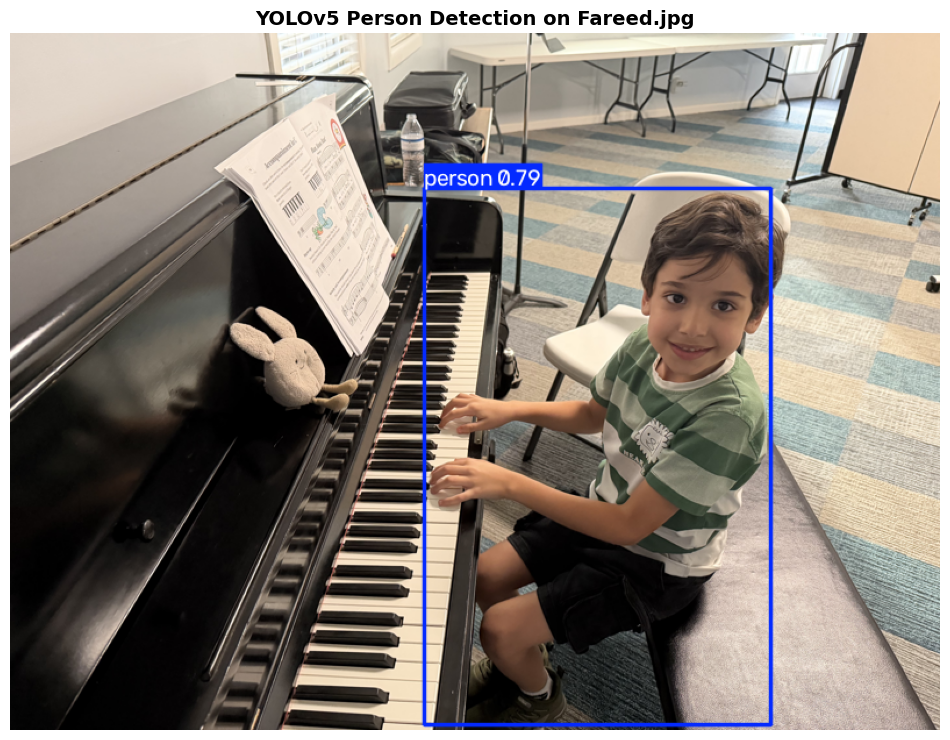

In [16]:
# Install required dependencies including ultralytics and pillow-heif
!pip install pillow-heif ultralytics --quiet

import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener

# Register HEIC opener with Pillow
register_heif_opener()

img_path = '/content/Fareed.jpg'

if os.path.exists(img_path):
    try:
        # 1. Explicitly load the PyTorch YOLOv5 model
        print("Loading YOLOv5 model...")
        yolo_model = torch.hub.load('ultralytics/yolov5', 'yolov5s', force_reload=False)

        # 2. Configure YOLOv5 to detect ONLY people (class index 0 is 'person')
        yolo_model.classes = [0]

        # 3. Open the HEIC image
        heic_img = Image.open(img_path)
        print(f"Successfully loaded image. Size: {heic_img.size}, Format: {heic_img.format}")

        # 4. Convert to a standard PIL RGB Image
        img_rgb = heic_img.convert('RGB')

        # 5. Resize to a standard dimension (e.g. 800x600) for fast & reliable inference
        resized_img = img_rgb.resize((800, 600))

        # 6. Convert to standard NumPy array
        img_array = np.array(resized_img)

        # 7. Run YOLOv5 inference
        results = yolo_model(img_array)

        # 8. Render results with bounding boxes
        results.render()
        annotated_img = Image.fromarray(results.ims[0])

        # 9. Display the detection result
        plt.figure(figsize=(12, 10))
        plt.imshow(annotated_img)
        plt.axis('off')
        plt.title('YOLOv5 Person Detection on Fareed.jpg', fontsize=14, fontweight='bold')
        plt.show()

    except Exception as e:
        print(f"An error occurred while loading or processing the image: {e}")
else:
    print(f"Error: File not found at '{img_path}'")